In [ ]:
import pandas as pd

# Load the dataset
file_path = 'clinical_trials_raw_patient2trial_conditions.csv'
df = pd.read_csv(file_path)

# Understand the dataset structure, columns, and data types
print("--- Dataset Info ---")
print(df.info())

print("\n--- First 5 Rows ---")
display(df.head())

# Select the 'Brief Summary' column and identify relevant disease labels/columns
print("\n--- Columns in Dataset ---")
print(df.columns.tolist())

summary_col = [col for col in df.columns if 'summary' in col.lower()]
if summary_col:
    print(f"\nIdentified 'Brief Summary' column as: {summary_col[0]}")
    brief_summaries = df[summary_col[0]]
else:
    print("\n'Brief Summary' column not found by name matching. Please check column list.")


--- Dataset Info ---
<class 'pandas.DataFrame'>
RangeIndex: 60337 entries, 0 to 60336
Data columns (total 16 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   source_condition_query  60337 non-null  str   
 1   nct_id                  60337 non-null  str   
 2   title                   60337 non-null  str   
 3   official_title          59551 non-null  str   
 4   brief_summary           60337 non-null  str   
 5   conditions              60336 non-null  str   
 6   interventions           54276 non-null  str   
 7   overall_status          60337 non-null  str   
 8   study_type              60337 non-null  str   
 9   phase                   23336 non-null  str   
 10  sex                     60304 non-null  str   
 11  minimum_age             57121 non-null  str   
 12  maximum_age             28400 non-null  str   
 13  healthy_volunteers      58857 non-null  object
 14  eligibility_criteria    60326 non-null  str 

,source_condition_query,nct_id,title,official_title,brief_summary,conditions,interventions,overall_status,study_type,phase,sex,minimum_age,maximum_age,healthy_volunteers,eligibility_criteria,clinicaltrials_url
0,breast cancer,NCT03676114,Effect of Perioperative Low Dose Ketamine on P...,Effect of Perioperative Low Dose Ketamine on P...,Breast cancer patients often have perioperativ...,Breast Cancer,ketamine | Normal saline,UNKNOWN,INTERVENTIONAL,PHASE4,FEMALE,20 Years,65 Years,False,Inclusion Criteria:\n\n1. American Society of ...,https://clinicaltrials.gov/study/NCT03676114
1,breast cancer,NCT02941614,Implementing Systematic Distress Screening in ...,Implementing Systematic Distress Screening in ...,Many breast cancer patients experience psychol...,Breast Cancer,Distress screening,COMPLETED,OBSERVATIONAL,NaN,ALL,18 Years,NaN,False,Inclusion Criteria:\n\n* Newly diagnosed with ...,https://clinicaltrials.gov/study/NCT02941614
2,breast cancer,NCT04509063,Investigating Public Enthusiasm for Mammograph...,Investigating Public Enthusiasm for Mammograph...,"Based on an American study by Scherer et al., ...",Breast Neoplasm Female | Mammography Screening...,Information about hypothetical mammography scr...,COMPLETED,INTERVENTIONAL,NaN,FEMALE,44 Years,49 Years,True,Inclusion Criteria:\n\n* Residence: Central De...,https://clinicaltrials.gov/study/NCT04509063
3,breast cancer,NCT04327063,MIRs 04 : Interpectoral Nerve Block With Ropiv...,A Double-blind Randomized Trial of Interpector...,Compare the effect of ropivacaine versus place...,Malignant Neoplasm of Breast,Saline | Ropivacaine,COMPLETED,INTERVENTIONAL,PHASE3,FEMALE,18 Years,85 Years,False,Inclusion Criteria:\n\n1. Women with non-metas...,https://clinicaltrials.gov/study/NCT04327063
4,breast cancer,NCT06778863,A Study of CLSP-1025 in Adult Patients With So...,GUARDIAN-101: A Phase 1 Dose Escalation and Ex...,Phase 1 dose escalation and expansion study of...,Advanced Solid Tumor | Unresectable Solid Tumo...,CLSP-1025,RECRUITING,INTERVENTIONAL,PHASE1,ALL,18 Years,NaN,False,Key Inclusion Criteria:\n\n* Patients must be ...,https://clinicaltrials.gov/study/NCT06778863



--- Columns in Dataset ---
['source_condition_query', 'nct_id', 'title', 'official_title', 'brief_summary', 'conditions', 'interventions', 'overall_status', 'study_type', 'phase', 'sex', 'minimum_age', 'maximum_age', 'healthy_volunteers', 'eligibility_criteria', 'clinicaltrials_url']

Identified 'Brief Summary' column as: brief_summary


In [4]:
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import LabelEncoder

# Download necessary NLTK data including the required punkt_tab
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('omw-1.4')

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\tonyr\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\tonyr\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\tonyr\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\tonyr\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\tonyr\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     C:\Users\tonyr\AppData\Roaming\nltk_data...


True

In [5]:
# 1. Handle missing values and remove duplicate records
initial_len = len(df)
df_clean = df.dropna(subset=['brief_summary', 'source_condition_query']).copy()
df_clean = df_clean.drop_duplicates(subset=['brief_summary'])
print(f"Removed {initial_len - len(df_clean)} rows containing duplicates or missing values.")
print(f"Remaining rows: {len(df_clean)}")

Removed 273 rows containing duplicates or missing values.
Remaining rows: 60064


In [6]:
# 2. Perform text cleaning, normalization, stop word removal, and lemmatization
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

def preprocess_text(text):
    if not isinstance(text, str):
        return ""
    # Convert to lowercase
    text = text.lower()
    # Remove punctuation and special characters
    text = re.sub(r'[^a-zA-Z\s]', '', text)
    # Tokenize
    tokens = nltk.word_tokenize(text)
    # Filter stop words and apply lemmatization
    cleaned_tokens = [lemmatizer.lemmatize(token) for token in tokens if token not in stop_words]
    return ' '.join(cleaned_tokens)

# Apply the preprocessing function
print("Cleaning and preprocessing text...")
df_clean['cleaned_summary'] = df_clean['brief_summary'].apply(preprocess_text)
print("Sample of cleaned text:")
display(df_clean[['brief_summary', 'cleaned_summary']].head(3))

Cleaning and preprocessing text...
Sample of cleaned text:


,brief_summary,cleaned_summary
0,Breast cancer patients often have perioperativ...,breast cancer patient often perioperative emot...
1,Many breast cancer patients experience psychol...,many breast cancer patient experience psycholo...
2,"Based on an American study by Scherer et al., ...",based american study scherer et al hypothesize...


In [7]:
# 3. Convert text data into numerical format using TF-IDF Vectorization
print("Converting text to TF-IDF features...")
tfidf = TfidfVectorizer(max_features=5000)
X = tfidf.fit_transform(df_clean['cleaned_summary'])
print(f"TF-IDF Matrix shape: {X.shape}")

Converting text to TF-IDF features...
TF-IDF Matrix shape: (60064, 5000)


In [8]:
# 4. Encode target labels for machine learning models
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(df_clean['source_condition_query'])
print(f"Unique categories encoded: {len(label_encoder.classes_)}")
print("Categories sample:", label_encoder.classes_[:5])

Unique categories encoded: 8
Categories sample: ['anxiety' 'breast cancer' 'chronic obstructive pulmonary disease'
 'covid-19' 'glaucoma']


--- Disease Category Distribution ---
source_condition_query
breast cancer                            16265
type 2 diabetes                          11395
covid-19                                 10102
anxiety                                   9259
chronic obstructive pulmonary disease     6141
rheumatoid arthritis                      3616
glaucoma                                  2150
sickle cell anemia                        1136
Name: count, dtype: int64


C:\Users\tonyr\AppData\Local\Temp\ipykernel_27532\135583498.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(y=category_counts.index, x=category_counts.values, palette='viridis')


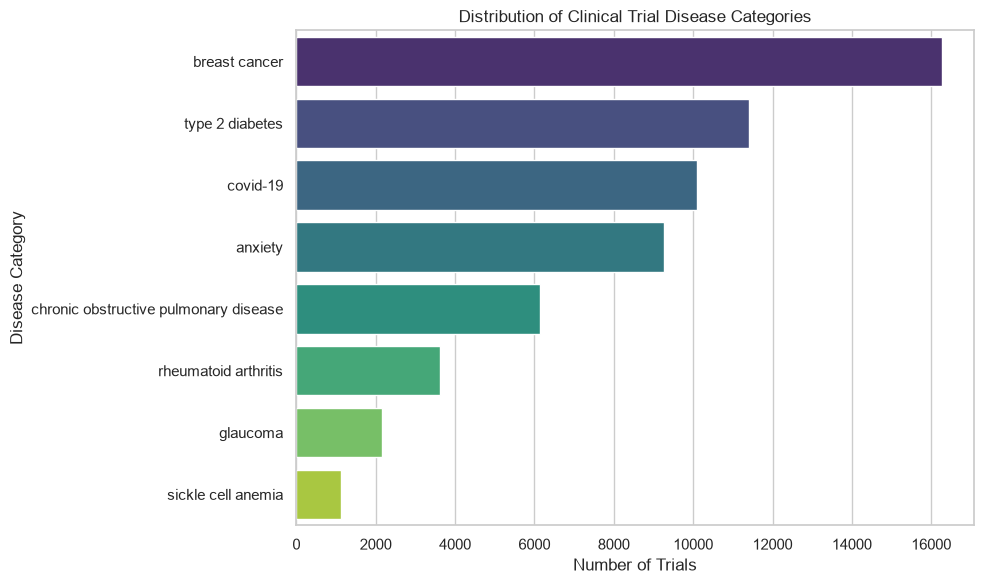

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

# Set plotting style
sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 6))

# 1. Analyze the distribution of disease categories
category_counts = df_clean['source_condition_query'].value_counts()
print("--- Disease Category Distribution ---")
print(category_counts)

sns.barplot(y=category_counts.index, x=category_counts.values, palette='viridis')
plt.title('Distribution of Clinical Trial Disease Categories')
plt.xlabel('Number of Trials')
plt.ylabel('Disease Category')
plt.tight_layout()
plt.show()

C:\Users\tonyr\AppData\Local\Temp\ipykernel_27532\3912639556.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_clean, y='source_condition_query', x='summary_length', palette='muted')


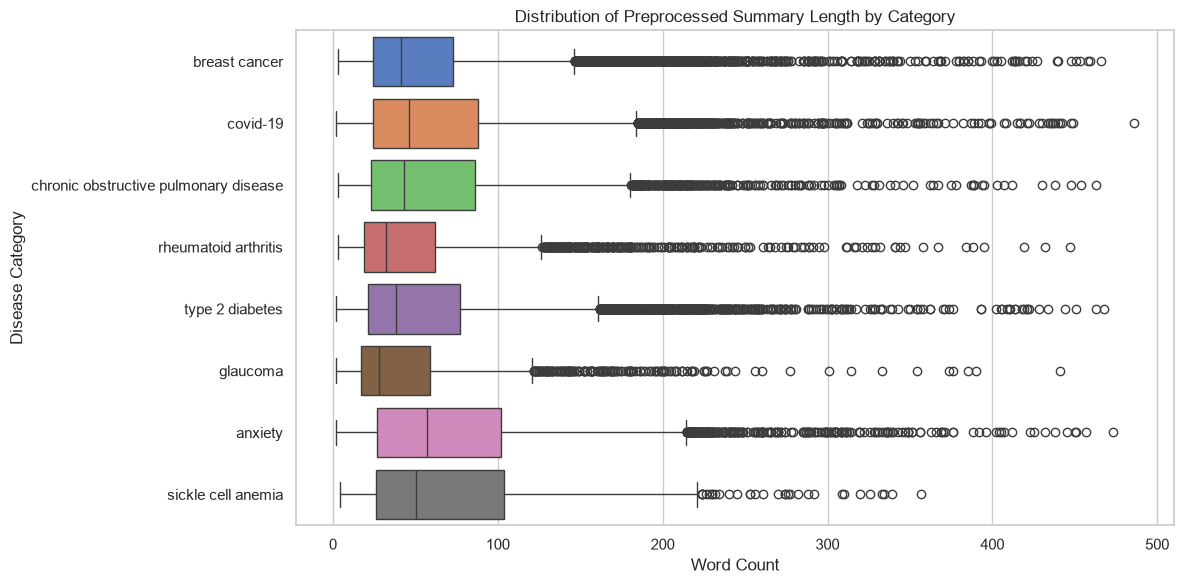

In [10]:
# 2. Analyze the length of text across different disease categories
df_clean['summary_length'] = df_clean['cleaned_summary'].apply(lambda x: len(x.split()))

plt.figure(figsize=(12, 6))
sns.boxplot(data=df_clean, y='source_condition_query', x='summary_length', palette='muted')
plt.title('Distribution of Preprocessed Summary Length by Category')
plt.xlabel('Word Count')
plt.ylabel('Disease Category')
plt.tight_layout()
plt.show()

C:\Users\tonyr\AppData\Local\Temp\ipykernel_27532\2661873520.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=common_words, x='Frequency', y='Word', palette='magma')


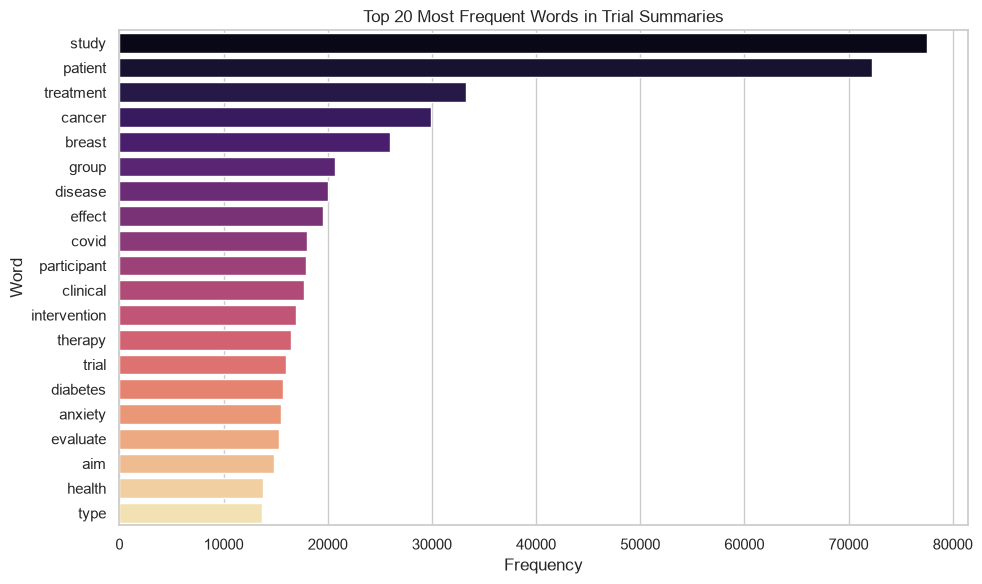

In [11]:
# 3. Identify the most common keywords and medical terms overall
all_words = ' '.join(df_clean['cleaned_summary']).split()
word_freq = Counter(all_words)
common_words = pd.DataFrame(word_freq.most_common(20), columns=['Word', 'Frequency'])

plt.figure(figsize=(10, 6))
sns.barplot(data=common_words, x='Frequency', y='Word', palette='magma')
plt.title('Top 20 Most Frequent Words in Trial Summaries')
plt.xlabel('Frequency')
plt.ylabel('Word')
plt.tight_layout()
plt.show()

In [12]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score

# 1. Split the preprocessed dataset into train and test sets (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print(f"Training set shape: {X_train.shape}")
print(f"Testing set shape: {X_test.shape}")

Training set shape: (48051, 5000)
Testing set shape: (12013, 5000)


In [13]:
# 2. Train a classification model (Logistic Regression)
print("Training the Logistic Regression model...")
model = LogisticRegression(max_iter=1000, random_state=42)
model.fit(X_train, y_train)

Training the Logistic Regression model...


,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lb

In [14]:
# 3. Evaluate the model performance
y_pred = model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
print(f"Model Accuracy: {accuracy * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=label_encoder.classes_))

Model Accuracy: 94.31%

Classification Report:
                                       precision    recall  f1-score   support

                              anxiety       0.89      0.96      0.92      1852
                        breast cancer       0.96      0.97      0.97      3253
chronic obstructive pulmonary disease       0.94      0.89      0.92      1228
                             covid-19       0.97      0.92      0.94      2021
                             glaucoma       0.98      0.92      0.95       430
                 rheumatoid arthritis       0.96      0.86      0.91       723
                   sickle cell anemia       0.96      0.85      0.90       227
                      type 2 diabetes       0.94      0.97      0.95      2279

                             accuracy                           0.94     12013
                            macro avg       0.95      0.92      0.93     12013
                         weighted avg       0.94      0.94      0.94     12013



In [15]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix

# 1. Split the preprocessed dataset into train and test sets (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print(f"Training set shape: {X_train.shape}")
print(f"Testing set shape: {X_test.shape}")

Training set shape: (48051, 5000)
Testing set shape: (12013, 5000)


In [16]:
# 2. Train a classification model (Logistic Regression)
print("Training the Logistic Regression model...")
model = LogisticRegression(max_iter=1000, random_state=42)
model.fit(X_train, y_train)

Training the Logistic Regression model...


,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lb

In [17]:
# 3. Evaluate the model performance
y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
print(f"Model Accuracy: {accuracy * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=label_encoder.classes_))

Model Accuracy: 94.31%

Classification Report:
                                       precision    recall  f1-score   support

                              anxiety       0.89      0.96      0.92      1852
                        breast cancer       0.96      0.97      0.97      3253
chronic obstructive pulmonary disease       0.94      0.89      0.92      1228
                             covid-19       0.97      0.92      0.94      2021
                             glaucoma       0.98      0.92      0.95       430
                 rheumatoid arthritis       0.96      0.86      0.91       723
                   sickle cell anemia       0.96      0.85      0.90       227
                      type 2 diabetes       0.94      0.97      0.95      2279

                             accuracy                           0.94     12013
                            macro avg       0.95      0.92      0.93     12013
                         weighted avg       0.94      0.94      0.94     12013



In [18]:
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score

# Train and evaluate our top-performing Linear Support Vector Classifier
print("Training the elite LinearSVC model...")
svc_model = LinearSVC(random_state=42, max_iter=2000)
svc_model.fit(X_train, y_train)

# Evaluate the model
y_pred_svc = svc_model.predict(X_test)
accuracy_svc = accuracy_score(y_test, y_pred_svc)
print(f"LinearSVC Model Accuracy: {accuracy_svc * 100:.2f}%")

Training the elite LinearSVC model...


LinearSVC Model Accuracy: 94.49%


In [19]:
import numpy as np

def predict_disease_category(raw_text):
    """
    Cleans a raw medical summary input, vectorizes it, and predicts
    the most probable disease category using the trained Logistic Regression model.
    """
    # 1. Clean and preprocess the input text using the same rules from Step 2
    cleaned_text = preprocess_text(raw_text)

    # 2. Vectorize the cleaned text using the fitted TF-IDF Vectorizer
    vectorized_text = tfidf.transform([cleaned_text])

    # 3. Predict the category probability distribution
    probabilities = model.predict_proba(vectorized_text)[0]
    predicted_class_idx = np.argmax(probabilities)
    confidence_score = probabilities[predicted_class_idx]

    # 4. Decode the integer index back to the human-readable class name
    predicted_category = label_encoder.inverse_transform([predicted_class_idx])[0]

    return predicted_category, confidence_score

# --- Demo of the Prediction System ---
sample_text_1 = """
This clinical trial evaluates a new dual-action chemotherapy regimen designed
to target HER2-positive metastatic breast carcinoma lesions and improve long-term progression-free
survival in female patients.
"""

sample_text_2 = """
A randomized, double-blind study to evaluate the safety and efficacy of
a novel oral SGLT2 inhibitor in controlling glucose levels and reducing HbA1c
in adults diagnosed with uncontrolled type 2 diabetes mellitus.
"""

for i, sample in enumerate([sample_text_1, sample_text_2], start=1):
    category, confidence = predict_disease_category(sample)
    print(f"--- Sample Input {i} ---")
    print(f"Text: {sample.strip()[:120]}...")
    print(f"Predicted Disease Category: {category.upper()}")
    print(f"Confidence Score: {confidence * 100:.2f}%\n")

--- Sample Input 1 ---
Text: This clinical trial evaluates a new dual-action chemotherapy regimen designed
to target HER2-positive metastatic breast ...
Predicted Disease Category: BREAST CANCER
Confidence Score: 99.72%

--- Sample Input 2 ---
Text: A randomized, double-blind study to evaluate the safety and efficacy of
a novel oral SGLT2 inhibitor in controlling gluc...
Predicted Disease Category: TYPE 2 DIABETES
Confidence Score: 99.90%



In [ ]:
import joblib

# Save our trained objects so they can be loaded inside the Streamlit app
joblib.dump(model, 'logistic_regression_model.pkl')
joblib.dump(svc_model, 'linear_svc_model.pkl')
joblib.dump(tfidf, 'tfidf_vectorizer.pkl')
joblib.dump(label_encoder, 'label_encoder.pkl')
print("Saved model, vectorizer, and label encoder to disk for Streamlit app.")

Saved model, vectorizer, and label encoder to disk for Streamlit app.
